In [12]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

In [13]:
# NOTE: If you get errors importing, run the following !pip... line,
# then restart your session (from Runtime menu) and comment out the pip line.
#!pip install gensim

import gensim.downloader as api

# download the wikipedia and twitter models
wiki = api.load('glove-wiki-gigaword-50')
twit = api.load('glove-twitter-50')

In [14]:
text = 'The quick brown fox jumps over a lazy dog'
words = set(text.lower().split(' '))
print(words)

def get_word_idx(word):
    return { 'wiki': wiki.key_to_index[word], 'twit': twit.key_to_index[word]}

for w in words:
    print(w, get_word_idx(w))

{'the', 'brown', 'quick', 'lazy', 'over', 'dog', 'jumps', 'fox', 'a'}
the {'wiki': 0, 'twit': 13}
brown {'wiki': 1042, 'twit': 1871}
quick {'wiki': 2582, 'twit': 2156}
lazy {'wiki': 16531, 'twit': 2222}
over {'wiki': 74, 'twit': 254}
dog {'wiki': 2926, 'twit': 1317}
jumps {'wiki': 11070, 'twit': 18014}
fox {'wiki': 2106, 'twit': 4000}
a {'wiki': 7, 'twit': 11}


In [21]:
text = 'The quick brown fox jumps over the lazy dog'

import re
words = re.split('\s',text.lower())

# index sequence in the two embeddings
wiki_idx = [wiki.key_to_index[w] if w in wiki.key_to_index else np.inf for w in words]
twit_idx = [twit.key_to_index[w] if w in twit.key_to_index else np.inf for w in words]

print(' Word |  Wiki | Twitter')
print('-'*23)
for o,w,t in zip(words,wiki_idx,twit_idx):
  print(f'{o:>5} | {w:>5} | {t:>5}')

 Word |  Wiki | Twitter
-----------------------
  the |     0 |    13
quick |  2582 |  2156
brown |  1042 |  1871
  fox |  2106 |  4000
jumps | 11070 | 18014
 over |    74 |   254
  the |     0 |    13
 lazy | 16531 |  2222
  dog |  2926 |  1317


<>:4: SyntaxWarning: invalid escape sequence '\s'
<>:4: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_118687/3433490100.py:4: SyntaxWarning: invalid escape sequence '\s'
  words = re.split('\s',text.lower())


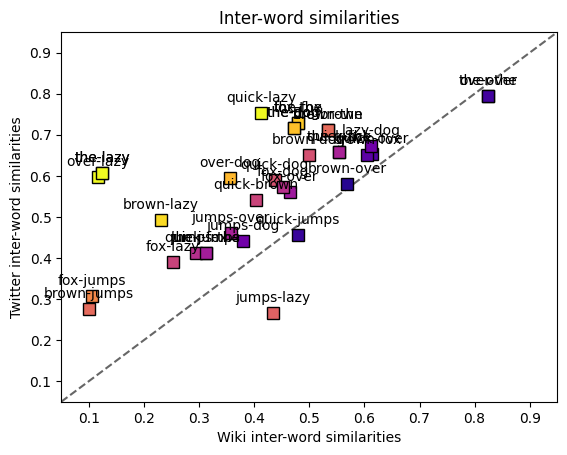

In [22]:
# start range at 0 or 1?
for i in range(0,len(words)):
  for j in range(i+1,len(words)):

    # skip identity
    if words[i]==words[j]: continue

    # calculate the cosine similarities for the two embeddings
    cs_wiki = wiki.similarity(wiki_idx[i],wiki_idx[j])
    cs_twit = twit.similarity(twit_idx[i],twit_idx[j])

    # calculate the distance to the unity line
    v = np.array([cs_wiki,cs_twit])
    u = np.array([1,1])
    dist = np.linalg.norm(v - (sum(v*u))/(np.linalg.norm(u)**2)*u)

    # draw the results at the coordinates
    plt.plot(cs_wiki,cs_twit,'ks',markersize=9,markerfacecolor=mpl.cm.plasma(dist*5))

    # and write the words
    plt.text(cs_wiki,cs_twit+.02,f'{words[i]}-{words[j]}',va='bottom',ha='center')


# plot the unity line
xylims = [.05,.95]
plt.plot(xylims,xylims,'--',color=[.4,.4,.4],zorder=-30)

# final adjustments
plt.gca().set(xlim=xylims,ylim=xylims,xlabel='Wiki inter-word similarities',
              ylabel='Twitter inter-word similarities',title='Inter-word similarities')
plt.show()